# Exercises week 43: reading a classifier — the confusion matrix, the ROC curve and the threshold

**FYS-STK3155/4155 Applied Data Analysis and Machine Learning**

**October 19–23, 2026**

**Deadline: Friday October 23 at midnight** (one notebook per group, in
Canvas).

## Aims of this week's exercises

Project 2 asks you to train classifiers — logistic regression as the
baseline and a neural network with hidden layers — and then to *say what
they do*: the confusion matrix on the test set, with its interpretation.
This week you build the tools for that, implementing them yourself from the
definitions and checking them against `scikit-learn`:

- the confusion matrix and the quantities read off its four counts —
  accuracy, precision, recall, $F_1$ (Section 5.12, Eqs. 5.67–5.70);
- the ROC curve and the area under it, the AUC, and why they measure
  something a single threshold cannot;
- (optional) the $K\times K$ confusion matrix of a multiclass classifier and
  how to read a $2\times2$ matrix off it.

The Monday lecture went through what every one of these measures *means* on
a worked screening example and then applied them to "is it a five?" on the
full MNIST set (`week43monday.pdf`, `week43monday.ipynb`); the Tuesday session
goes through the worked example in detail and then writes the same code on
the small digits set (`week43tuesday.ipynb`). The classifiers can be your
own Project 2 code (recommended: this is the code you will report on) or
`scikit-learn`'s `LogisticRegression` and `MLPClassifier`.

There is no validation set and no cross-validation in this week's
exercises: how to cross-validate your Project 2 network is the topic of next
week's Tuesday session and exercises.

**Reading:** Sections 5.12–5.13 of the lecture notes; Eq. (2.24) for the
standard error of a proportion. Hastie, Tibshirani and Friedman, Section
9.2.5; Raschka et al., Chapter 6 ("Looking at different performance
evaluation metrics").

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import metrics as skm
np.random.seed(2026)

## Exercise 1: your own confusion matrix, ROC curve and AUC, checked

Implement the following functions from their definitions. Labels are in
$\{0,1\}$ with $1$ the positive class; `scores` are the output probabilities
(or any monotone score) of a classifier.

**a)** `confusion_matrix(y_true, y_pred)` returning the four counts
`tp, fn, fp, tn` of Eq. (5.67), and from them the accuracy, precision,
recall and $F_1$ of Eqs. (5.68)–(5.70) (handle the cases where a
denominator is zero).

**b)** `roc_curve(y_true, scores)` returning the false positive rates, true
positive rates and thresholds for every distinct score, from **one sorted
pass**: sort by decreasing score and walk down the list — every sample
flagged adds one to TP if it is a positive and one to FP if it is a
negative; then `auc_trapezoid(fpr, tpr)` for the area.

**c)** `roc_auc(y_true, scores)` by the rank formula of the lecture,
$\mathrm{AUC}=\bigl(\sum_{i\in\mathrm{pos}}R_i-\tfrac12 n_+(n_++1)\bigr)/(n_+n_-)$,
with average ranks for tied scores (`np.unique` with `return_inverse` and
`return_counts`, or `scipy.stats.rankdata`). Explain in one sentence why
this is the probability that a random positive outscores a random negative.

**d)** Test everything on the small example below against `sklearn.metrics`
(`confusion_matrix`, `precision_score`, `recall_score`, `f1_score`,
`roc_curve` with `drop_intermediate=False`, `roc_auc_score`). Mind the
layout of `sklearn.metrics.confusion_matrix`: rows true $0/1$, columns
predicted $0/1$, so `[[TN, FP], [FN, TP]]`. The example has tied scores on
purpose: the three AUCs must still agree.

In [9]:
def confusion_matrix(y_true, y_pred):
    y_true , y_pred = np.asarray(y_true), np.asarray(y_pred)
    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    return tp, fn, fp, tn

def classification_report(y_true, y_pred):
    # accuracy, precision, recall and F1 from the four counts
    tp, fn, fp, tn = confusion_matrix(y_true=y_true, y_pred=y_pred)
    n = tp + fn + fp + tn

    accuracy = (tp + tn) / n if (n != 0) else 0
    precision = tp / (tp + fp) if (tp + fp) != 0 else 0
    recall = tp / (tp + fn) if (tp + fn) != 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) != 0 else 0

    return accuracy, precision, recall, f1 

def roc_curve(y_true, scores):
    y_true, scores = np.asarray(y_true), np.asarray(scores)
    order = np.argsort(-scores)
    y_true_sort, scores_sort = y_true[order], scores[order]
    tp, fp = np.cumsum(y_true_sort == 1), np.cumsum(y_true_sort == 0)
    last = np.r_[True, scores_sort[1:] != scores_sort[:-1]]
    tpr = np.r_[0.0, tp[last] / max(tp[-1], 1)]
    fpr = np.r_[0.0, fp[last] / max(fp[-1], 1)]
    thresholds = np.r_[np.inf, scores_sort[last]]
    return fpr, tpr, thresholds

def auc_trapezoid(fpr, tpr):
    return np.sum(np.diff(fpr) * (tpr[1:] + tpr[:-1]) / 2)

def roc_auc(y_true, scores):
    y_true, scores = np.asarray(y_true), np.asarray(scores)
    _, inv, cnt = np.unique(scores, return_inverse=True, return_counts=True)
    first = np.cumsum(cnt) - cnt + 1                  # rank of the first member of each tie group
    ranks = (first + (cnt - 1) / 2)[inv]              # average rank within the group
    n_pos = int(np.sum(y_true == 1))
    n_neg = len(y_true) - n_pos
    S = np.sum(ranks[y_true == 1]) - n_pos * (n_pos + 1) / 2
    return float(S / (n_pos * n_neg))


# a small test: 20 samples, 6 positives, scores rounded to one decimal so that there are ties
rng = np.random.default_rng(2)
y_small = np.array([1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0])
s_small = np.round(np.clip(0.35 * y_small + rng.normal(0.3, 0.2, 20), 0, 1), 1)
print(confusion_matrix(y_small, s_small > 0.5), skm.confusion_matrix(y_small, s_small > 0.5))
print(roc_auc(y_small, s_small), auc_trapezoid(*roc_curve(y_small, s_small)[:2]), skm.roc_auc_score(y_small, s_small))

(np.int64(5), np.int64(1), np.int64(1), np.int64(13)) [[13  1]
 [ 1  5]]
0.8571428571428571 0.7797619047619048 0.8571428571428571


**The same with `scikit-learn`.** Once your functions agree with the
library, this is the template you can use in Project 2 for the test set
(`y_test` the true labels, `p_test` the output probabilities of your
classifier, `y_pred = p_test > 0.5` the decisions):

[[13  1]
 [ 1  5]]
accuracy 0.9000  precision 0.8333  recall 0.8333  F1 0.8333
              precision    recall  f1-score   support

    negative       0.93      0.93      0.93        14
    positive       0.83      0.83      0.83         6

    accuracy                           0.90        20
   macro avg       0.88      0.88      0.88        20
weighted avg       0.90      0.90      0.90        20

AUC 0.8571


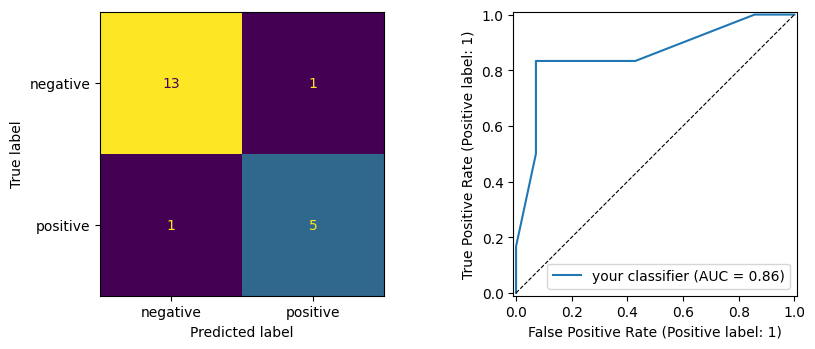

: 

In [ ]:
from sklearn.metrics import (confusion_matrix as sk_confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score, precision_score, recall_score, f1_score,
                             classification_report as sk_classification_report,
                             roc_curve as sk_roc_curve, roc_auc_score, RocCurveDisplay)

y_test, p_test = y_small, s_small          # replace by your test labels and output probabilities
y_pred = p_test > 0.5

cm = sk_confusion_matrix(y_test, y_pred)   # [[TN, FP], [FN, TP]]
print(cm)
print(f"accuracy {accuracy_score(y_test, y_pred):.4f}  precision {precision_score(y_test, y_pred, zero_division=0):.4f}  "
      f"recall {recall_score(y_test, y_pred):.4f}  F1 {f1_score(y_test, y_pred):.4f}")
print(sk_classification_report(y_test, y_pred, target_names=["negative", "positive"], zero_division=0))

fpr, tpr, thresholds = sk_roc_curve(y_test, p_test, drop_intermediate=False)
print(f"AUC {roc_auc_score(y_test, p_test):.4f}")

fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
ConfusionMatrixDisplay(cm, display_labels=["negative", "positive"]).plot(ax=ax[0], colorbar=False)
RocCurveDisplay.from_predictions(y_test, p_test, ax=ax[1], name="your classifier")
ax[1].plot([0, 1], [0, 1], "k--", lw=0.8)
plt.tight_layout(); plt.show()

## Exercise 2: MNIST, one digit against the rest

This is the Monday lecture's example on data of your choosing, with your
Project 2 code. Use the full MNIST set as described in Project 2 (the file
`mnist.npz`, 60 000 training and 10 000 test images, flattened and scaled to
$[0,1]$); if your laptop is slow, train on a subset of the training images
but evaluate on the full test set.

**a)** Pick a digit $d$ (the lecture used $5$; choose a different one) and
set $y=1$ for the images of $d$. Report the prevalence of $d$ in the test set
and the accuracy of the majority rule ("never $d$") — the number every
accuracy below must be compared with.

**b)** Train logistic regression (no hidden layer, sigmoid output, cross
entropy) and a network with one hidden layer on the training set, with the
SGD of Project 2. On the test set, at threshold $0.5$, report for both the
confusion matrix in the layout of Eq. (5.67) and the accuracy, precision,
recall and $F_1$ from your own exercise-1 functions, checked against the
`scikit-learn` template. Say in two sentences what the matrices tell you
that the two accuracies do not, and what fraction of the remaining error
(relative to the majority rule) each classifier removed.

**c)** The ROC curves of both classifiers in one figure, with the AUC by
your trapezoidal rule, by your rank formula and by `roc_auc_score`, and the
point corresponding to $t=0.5$ marked on each curve. Add a histogram of the
output probabilities of the test images, separately for the two classes,
on a logarithmic vertical axis. Where do the errors live, and what does the
difference between the two AUCs say that the confusion matrices at $0.5$ do
not?

**d)** Standard errors: of the test accuracy and of the recall (Eq. 2.24,
$\sqrt{\hat p(1-\hat p)/n}$ with the appropriate $n$ in each case). Would
you call the difference between your two classifiers significant?

In [ ]:
# your Project 2 network (or the week-41 code: create_layers, feed_forward, backpropagation, train, predict)
##################### solution ######################################

def create_layers_batch(network_input_size, layer_output_sizes):
    layers = []
    i_size = network_input_size
    for layer_output_size in layer_output_sizes:
        W = np.random.randn(i_size, layer_output_size)
        b = np.random.randn(layer_output_size)
        layers.append((W, b))
        i_size = layer_output_size
    return layers


def feed_forward_batch(inputs, layers, activation_funcs):
    a = inputs
    for (W, b), activation_func in zip(layers, activation_funcs):
        a = activation_func(a @ W + b)
    return a


def feed_forward_saver_batch(inputs, layers, activation_funcs):
    layer_inputs, zs = [], []
    a = inputs
    for (W, b), activation_func in zip(layers, activation_funcs):
        layer_inputs.append(a)
        z = a @ W + b
        a = activation_func(z)
        zs.append(z)
    return layer_inputs, zs, a


def mse_der_batch(predict, target):
    return 2 * (predict - target) / predict.size


def cost_batch(layers, inputs, activation_funcs, targets):
    return mse_der_batch(feed_forward_batch(inputs, layers, activation_funcs), targets)


def backpropagation_batch(
    inputs, layers, activation_funcs, targets, activation_ders, cost_der=mse_der_batch
):
    layer_inputs, zs, predict = feed_forward_saver_batch(inputs, layers, activation_funcs)
    layer_grads = [() for layer in layers]

    for i in reversed(range(len(layers))):
        layer_input, z, activation_der = layer_inputs[i], zs[i], activation_ders[i]
        if i == len(layers) - 1:
            dC_da = cost_der(predict, targets)
        else:
            (W, b) = layers[i + 1]
            dC_da = dC_dz @ W.T                 # samples stay in the rows
        dC_dz = dC_da * activation_der(z)       # (n, n_out), one error vector per sample
        dC_dW = layer_input.T @ dC_dz           # sum over the samples of the outer products
        dC_db = np.sum(dC_dz, axis=0)           # sum over the samples of the errors
        layer_grads[i] = (dC_dW, dC_db)

    return layer_grads


###################################


d = ...                                # your digit
data = np.load("mnist.npz")            # see Project 2 for where to get it
x_train = data["x_train"].reshape(len(data["x_train"]), -1) / 255.0
x_test = data["x_test"].reshape(len(data["x_test"]), -1) / 255.0
y_train = (data["y_train"] == d).astype(float)
y_test = (data["y_test"] == d).astype(float)
...

## Exercise 3 (optional): ten classes — the matrix Project 2 asks for

**a)** Train your softmax network (or `scikit-learn`'s `MLPClassifier`, or
the week-41 `[784, 100, 10]` network) on the MNIST training set and build
the $10\times10$ confusion matrix of the test set by hand ($C_{ij}$ = number
of test images of true class $i$ predicted as class $j$; `np.add.at` does it
in one line). Check it against `sklearn.metrics.confusion_matrix`.

**b)** From the matrix: the per-class precision (columns) and recall (rows),
checked against `sklearn.metrics.classification_report`; the five most
frequent confusions (true $\to$ predicted); the $2\times2$ matrix of your
digit $d$ against the rest, read off the big matrix. Compare the latter with
the binary classifiers of exercise 2: same model? same decision rule? which
is better, and why?

**c)** Plot the matrix as an image with the diagonal removed, annotated with
the counts, and the per-class precision and recall as bars. Which pairs of
digits are confused in *both* directions, and which only in one? Look at a
few of the confused images and say whether you would have got them right.

**d)** The test accuracy comes with the standard error of Eq. (2.24). Train
a second network with a different architecture or a different seed and
report both accuracies with their error bars. Is the difference
significant? How many test images would you need to resolve a difference of
$0.1$ percentage points at $97\%$ accuracy?

In [ ]:
...

## Insights you should have gained this week — a self-check

Before you hand in, go through the list below without looking at the notes.
Each row is a question we may ask in the Tuesday session or on Project 2;
the right-hand column is the insight it tests, in one sentence.

| Ask yourself | The insight it tests |
|---|---|
| A classifier scores $97\%$ accuracy. Is it good? | Not knowable without the majority-class accuracy: on a problem with $9\%$ positives, $91\%$ is free, and the honest number is the fraction of the *remaining* error removed. Accuracy is $\pi\,\mathrm{recall}+(1-\pi)\,\mathrm{specificity}$, blind to the rare class. |
| What are the four numbers everything else is made of? | TP, FN, FP, TN — the confusion matrix (Eq. 5.67), rows true and columns predicted; the two off-diagonal entries are two *different* errors with different costs. |
| Precision or recall — which one do I want? | A question about the application, not the model: screening wants recall (few misses), a spam filter wants precision (few false alarms); the threshold trades one for the other. |
| Why the harmonic mean in $F_1$? | It is small unless *both* precision and recall are large ($F_1\le2\min$); the arithmetic mean would reward a classifier that is perfect on one and useless on the other. |
| What does an AUC of $0.99$ mean? | Pick a random positive and a random negative: with probability $0.99$ the positive gets the higher score. It depends on the ranking alone — not on the threshold, not on the class balance. |
| The threshold moved from $0.5$ to $0.1$. What changed? | Only the operating point: weights, probabilities, ranking, ROC curve and AUC are identical; every number computed from the four counts changed, and accuracy can fall while recall rises. |
| Why is the ROC curve blind to class imbalance and the PR curve not? | TPR and FPR are each normalised within one class; precision has FP in its denominator, so the proportion of positives enters it — the PR floor is the prevalence. |
| What does the MCC add to precision and recall? | It is the correlation between labels and decisions, uses all four counts, is symmetric in the classes, and is $0$ for the majority rule — the one scalar that is hard to fool by imbalance. |
| Rows or columns of the $10\times10$ matrix? | Rows are the truth: a row over its sum is the recall of that class; columns are the decisions: a column over its sum is its precision. |
| How accurate is an accuracy? | It is a binomial proportion: standard error $\sqrt{\hat p(1-\hat p)/n}$ (Eq. 2.24) — $\pm0.15\%$ on $10\,000$ images, $\pm1.7\%$ on $143$; differences inside the error bar are not differences. |
| Why do we train on the cross entropy and report accuracy? | Accuracy is a step function of the parameters with zero gradient; the cross entropy is a smooth surrogate minimised in roughly the same place — a lower cross entropy does not guarantee a higher accuracy. |

### Practicalities

Deliver your solutions (a single Jupyter notebook) in Canvas before
**Friday October 23 at midnight**. Collaboration is encouraged — list your
collaborators. The functions you write this week are the ones you will use
in part e) of Project 2 (deadline November 6); the solutions to the
exercises of weeks 41 and 42 are in the weekly material folders of the
course repository. Validation sets and cross-validation for your Project 2
network are the topic of week 44.

**Declaration of the use of large language models (LLMs).** Many of you use
ChatGPT, Claude, Copilot or similar tools when solving the weekly exercises,
and that is fine — but it has to be declared, for the weekly exercises as
well as for the projects. Add a short paragraph at the end of your notebook
(the cell below is a template) stating which tools you used and for what
(code, debugging, explanations, text), or that you did not use any. A few
sentences are enough; the full guidelines, which you must follow in the
project reports, are at
[LLM_Usage_Declaration_Guidelines.md](https://github.com/EducationalMaterialUiO/MachineLearningUiO/blob/main/LLM_Usage_Declaration_Guidelines.md). Remember that *you* are
responsible for every line you hand in: be prepared to explain it.

## Declaration of the use of LLMs

*(Replace this text with your own declaration, or write "No LLMs were used".)*

Tools used: … (for example ChatGPT, Claude, GitHub Copilot)

What they were used for: … (for example debugging the sorted pass in
exercise 1, explaining the rank formula in exercise 1c, polishing this text)

What was done without them: …